In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
df = pd.read_csv('viral_videos.csv')
print(f"Shape: {df.shape[0]} rows, {df.shape[1]} columns")
df.head()

Shape: 12000 rows, 15 columns


,video_id,category,duration_sec,title_length,thumbnail_face,upload_hour,upload_day,tags_count,description_length,subscriber_count,views,likes,comments,shares,viral
0,vid_000001,Beauty,517,64,1,23,Wed,27,429,907474,970600,20610,4029,7208,1
1,vid_000002,Tech,495,47,1,23,Mon,10,222,1004641,104278,3907,554,554,0
2,vid_000003,Beauty,311,76,0,17,Mon,13,520,168170,18102,1021,77,122,0
3,vid_000004,Fitness,590,69,0,0,Mon,17,309,285593,52042,2587,142,964,0
4,vid_000005,Tech,380,58,1,19,Mon,0,101,1073326,908509,22993,1825,2611,1


In [4]:
#check missiong values, duplicate rows and data types
print("--- Data Hygirnr Report ---")
print(f"total rows:{len(df)}")
print(f"Duplicate Rows: {df.duplicated().sum()}")

print("\n--- Missing values per column ---")
missing =df.isnull().sum()
print(missing[missing>0] if missing.sum() > 0 else "no missing values found!")

print("\n--- Column Data Types ---")
print(df.dtypes)

--- Data Hygirnr Report ---
total rows:12000
Duplicate Rows: 0

--- Missing values per column ---
no missing values found!

--- Column Data Types ---
video_id                  str
category                  str
duration_sec            int64
title_length            int64
thumbnail_face          int64
upload_hour             int64
upload_day                str
tags_count              int64
description_length      int64
subscriber_count        int64
views                   int64
likes                   int64
comments                int64
shares                  int64
viral                   int64
like_ratio            float64
comment_ratio         float64
dtype: object


In [5]:
#1. Calculate the 80th percentile cutoff for views
viral_cutoff = df['views'].quantile(0.80)
print(f"Virality Cutoff(80the percentile):{viral_cutoff:,.0f}views")

#create binary target column 'is_viral'(1 if views >=cutoff, else 0)
df['is_viral'] = (df['views'] >= viral_cutoff).astype(int)

# 3. Check class balance (should be 20% viral / 80% non-viral)
print('\n Target class Distribution: ')
print(df['is_viral'].value_counts(normalize=True))

Virality Cutoff(80the percentile):734,315views

 Target class Distribution: 
is_viral
0    0.8
1    0.2
Name: proportion, dtype: float64


In [6]:
#like ratio and com
df['like_ratio'] = (df['likes']/df['views'].replace(0,np.nan)).fillna(0)
df['comment_ratio'] = (df['comments']/df['views'].replace(0,np.nan)).fillna(0)
stats = df.groupby('is_viral')[['like_ratio','comment_ratio']].agg(['mean','median','std'])
print(stats)

         like_ratio                     comment_ratio                    
               mean    median       std          mean    median       std
is_viral                                                                 
0          0.050286  0.050288  0.017356      0.006262  0.005663  0.003143
1          0.049295  0.049587  0.017379      0.006202  0.005527  0.003148


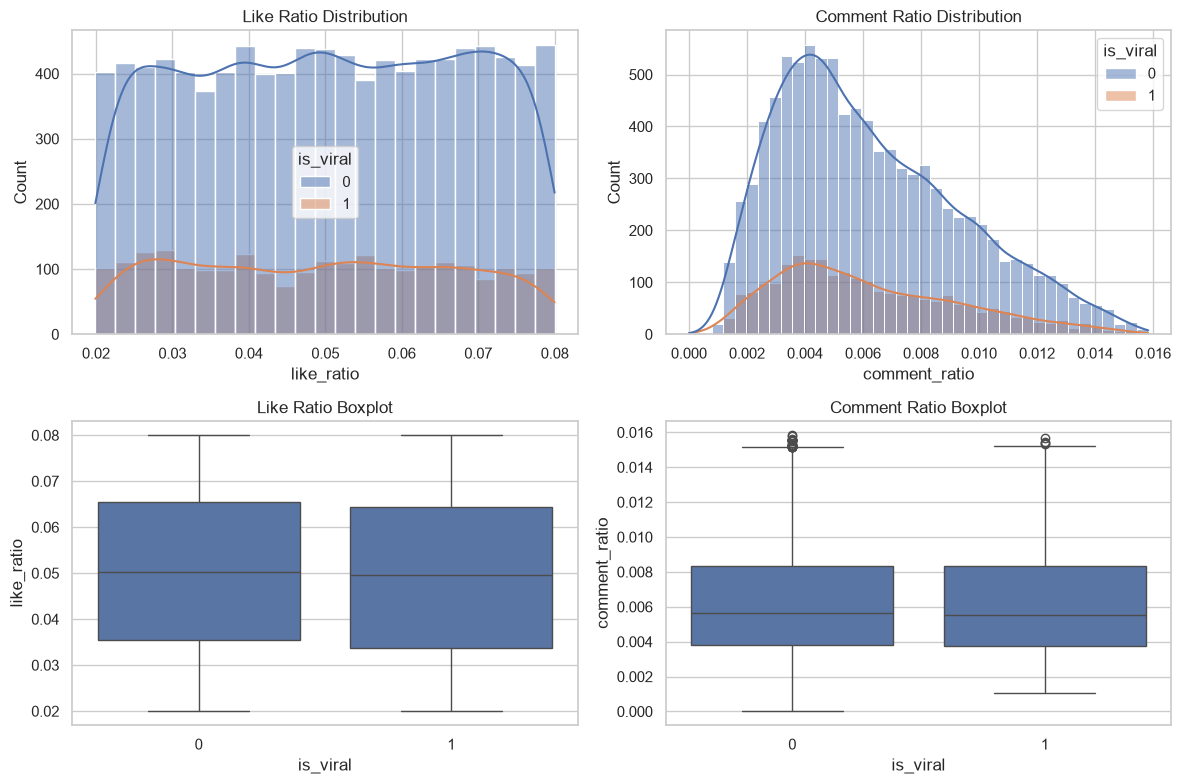

In [11]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set plot style
sns.set_theme(style="whitegrid")

# Create a 2x2 subplot grid
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# 1. Distribution of Like Ratio
sns.histplot(data=df, x='like_ratio', hue='is_viral', kde=True, ax=axes[0, 0])
axes[0, 0].set_title("Like Ratio Distribution")

# 2. Distribution of Comment Ratio
sns.histplot(data=df, x='comment_ratio', hue='is_viral', kde=True, ax=axes[0, 1])
axes[0, 1].set_title("Comment Ratio Distribution")

# 3. Boxplot of Like Ratio
sns.boxplot(data=df, x='is_viral', y='like_ratio', ax=axes[1, 0])
axes[1, 0].set_title("Like Ratio Boxplot")

# 4. Boxplot of Comment Ratio
sns.boxplot(data=df, x='is_viral', y='comment_ratio', ax=axes[1, 1])
axes[1, 1].set_title("Comment Ratio Boxplot")

plt.tight_layout()
plt.show()

In [12]:
# Cell 6: Category-level engagement summary
category_stats = df.groupby('category')[['like_ratio', 'comment_ratio']].agg(['mean', 'median', 'count'])

# Sort by median like_ratio descending to see top performing categories first
category_stats_sorted = category_stats.sort_values(by=('like_ratio', 'median'), ascending=False)

print(category_stats_sorted)

          like_ratio                 comment_ratio                
                mean    median count          mean    median count
category                                                          
Science     0.051419  0.052247   808      0.006471  0.005869   808
News        0.050811  0.051657   825      0.006402  0.005770   825
Education   0.050539  0.051361   764      0.006304  0.005610   764
Finance     0.050694  0.051180   821      0.006393  0.005711   821
Beauty      0.050487  0.050994   817      0.006265  0.005722   817
Travel      0.050619  0.050786   807      0.006185  0.005599   807
DIY         0.050169  0.050554   779      0.006189  0.005740   779
Vlog        0.050077  0.050219   821      0.006262  0.005543   821
Gaming      0.050320  0.050203   807      0.006318  0.005589   807
Tech        0.050227  0.049792   824      0.006308  0.005888   824
Fitness     0.049612  0.049649   776      0.006203  0.005618   776
Cooking     0.049468  0.049519   794      0.006077  0.005527  